<a href="https://colab.research.google.com/github/sushants05-ops/ECGR-4105---Intro-to-Machine-Learning/blob/main/ECGR_4105_Homework_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Problem 1 | Model: linear | LR: 0.1000 | Epoch:  500 | Loss: 0.034817
Problem 1 | Model: linear | LR: 0.1000 | Epoch: 1000 | Loss: 0.034817
Problem 1 | Model: linear | LR: 0.1000 | Epoch: 1500 | Loss: 0.034817
Problem 1 | Model: linear | LR: 0.1000 | Epoch: 2000 | Loss: 0.034817
Problem 1 | Model: linear | LR: 0.1000 | Epoch: 2500 | Loss: 0.034817
Problem 1 | Model: linear | LR: 0.1000 | Epoch: 3000 | Loss: 0.034817
Problem 1 | Model: linear | LR: 0.1000 | Epoch: 3500 | Loss: 0.034817
Problem 1 | Model: linear | LR: 0.1000 | Epoch: 4000 | Loss: 0.034817
Problem 1 | Model: linear | LR: 0.1000 | Epoch: 4500 | Loss: 0.034817
Problem 1 | Model: linear | LR: 0.1000 | Epoch: 5000 | Loss: 0.034817
Problem 1 | Model: quadratic | LR: 0.1000 | Epoch:  500 | Loss: 0.031659
Problem 1 | Model: quadratic | LR: 0.1000 | Epoch: 1000 | Loss: 0.031659
Problem 1 | Model: quadratic | LR: 0.1000 | Epoch: 1500 | Loss: 0.031659
Problem 1 | Model: quadratic | LR: 0.1000 | Epoch: 2000 | Loss: 0.031659
Problem 

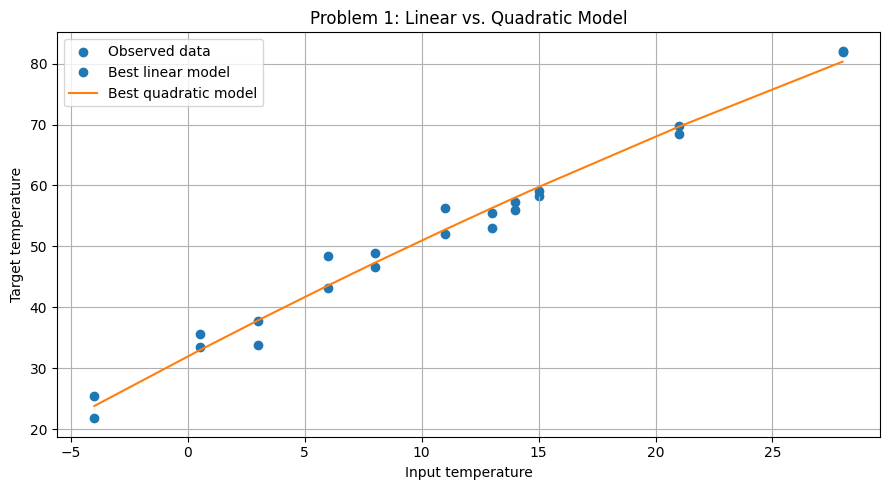


Problem 2: Features used
['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Training models...
Problem 2 | LR: 0.1000 | Epoch:  500 | Train Loss: 0.444339 | Validation Loss: 0.431341 | Validation Accuracy (within 10%): 35.78%
Problem 2 | LR: 0.1000 | Epoch: 1000 | Train Loss: 0.444339 | Validation Loss: 0.431341 | Validation Accuracy (within 10%): 35.78%
Problem 2 | LR: 0.1000 | Epoch: 1500 | Train Loss: 0.444339 | Validation Loss: 0.431341 | Validation Accuracy (within 10%): 35.78%
Problem 2 | LR: 0.1000 | Epoch: 2000 | Train Loss: 0.444339 | Validation Loss: 0.431341 | Validation Accuracy (within 10%): 35.78%
Problem 2 | LR: 0.1000 | Epoch: 2500 | Train Loss: 0.444339 | Validation Loss: 0.431341 | Validation Accuracy (within 10%): 35.78%
Problem 2 | LR: 0.1000 | Epoch: 3000 | Train Loss: 0.444339 | Validation Loss: 0.431341 | Validation Accuracy (within 10%): 35.78%
Problem 2 | LR: 0.1000 | Epoch: 3500 | Train Loss: 0.444339 | Validation Loss: 0.431341 | Validation Accuracy (w

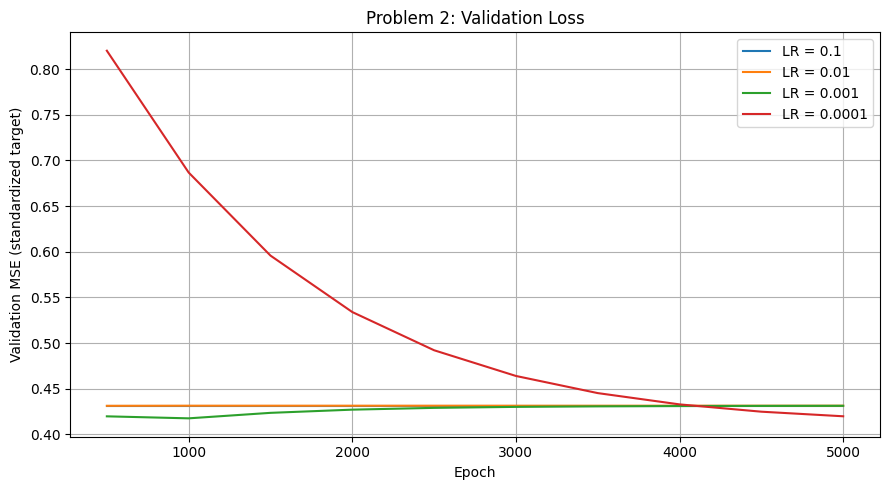

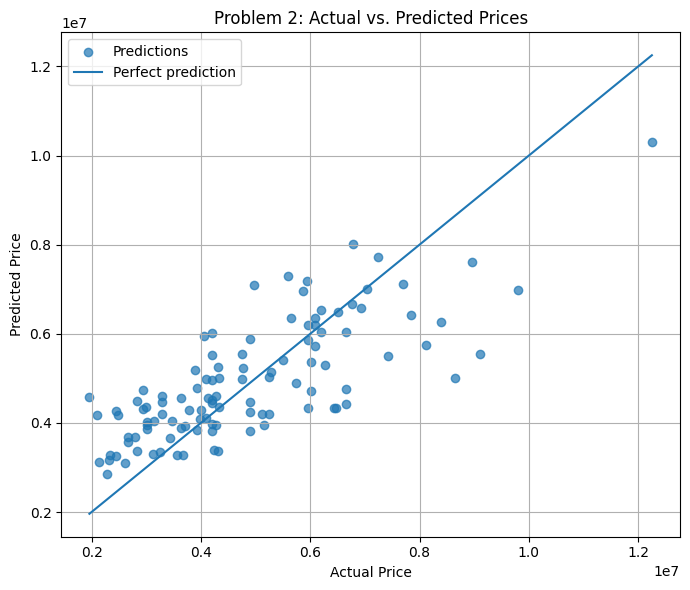


Problem 3: Features used
['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'mainroad_no', 'mainroad_yes', 'guestroom_no', 'guestroom_yes', 'basement_no', 'basement_yes', 'hotwaterheating_no', 'hotwaterheating_yes', 'airconditioning_no', 'airconditioning_yes', 'prefarea_no', 'prefarea_yes', 'furnishingstatus_furnished', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']

Training models...
Problem 3 | LR: 0.1000 | Epoch:  500 | Train Loss: 0.325939 | Validation Loss: 0.312707 | Validation Accuracy (within 10%): 33.94%
Problem 3 | LR: 0.1000 | Epoch: 1000 | Train Loss: 0.325939 | Validation Loss: 0.312707 | Validation Accuracy (within 10%): 33.94%
Problem 3 | LR: 0.1000 | Epoch: 1500 | Train Loss: 0.325939 | Validation Loss: 0.312707 | Validation Accuracy (within 10%): 33.94%
Problem 3 | LR: 0.1000 | Epoch: 2000 | Train Loss: 0.325939 | Validation Loss: 0.312707 | Validation Accuracy (within 10%): 33.94%
Problem 3 | LR: 0.1000 | Epoch: 2500 | Train Loss: 0.325939 |

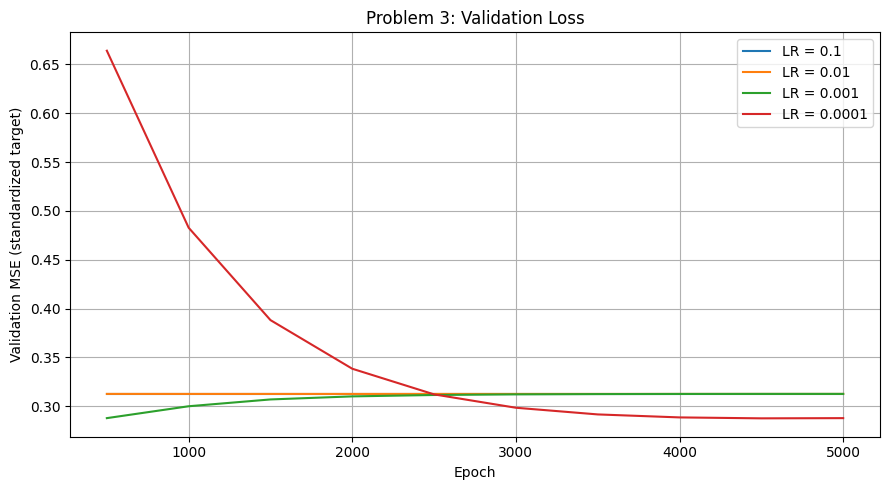

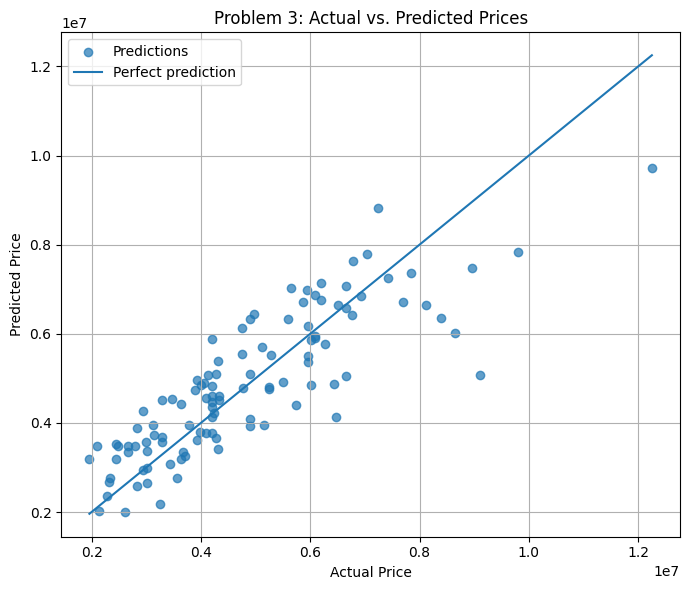


Homework 5: Problem 2 vs. Problem 3
-----------------------------------
Problem 2 best learning rate: 0.0001
Problem 2 validation MSE: 1461545598731.59
Problem 2 validation MAE: 946324.32
Problem 2 validation R-squared: 0.5857
Problem 2 accuracy within 10%: 33.94%

Problem 3 best learning rate: 0.0001
Problem 3 validation MSE: 1002516542728.10
Problem 3 validation MAE: 774513.98
Problem 3 validation R-squared: 0.7158
Problem 3 accuracy within 10%: 34.86%

Problem 3 has the lower validation MSE.


In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Problem 1
torch.manual_seed(42)
np.random.seed(42)
torch.set_default_dtype(torch.float64)

learning_rates = [0.1, 0.01, 0.001, 0.0001]
epochs = 5000
report_every = 500

# Temperature data from the lecture example
t_u = torch.tensor([
    0.5, 14.0, 15.0, 28.0, 11.0, 8.0,
    3.0, -4.0, 6.0, 13.0, 21.0
])

t_c = torch.tensor([
    35.7, 55.9, 58.2, 81.9, 56.3, 48.9,
    33.9, 21.8, 48.4, 53.0, 68.4
])

# Normalize the input and target for stable training
t_mean = t_u.mean()
t_std = t_u.std(unbiased=False)
c_mean = t_c.mean()
c_std = t_c.std(unbiased=False)

t_norm = (t_u - t_mean) / t_std
c_norm = (t_c - c_mean) / c_std


def train_temperature(model_type, learning_rate):
    if model_type == "linear":
        parameters = torch.zeros(2, requires_grad=True)
    else:
        parameters = torch.zeros(3, requires_grad=True)

    loss_history = []

    for epoch in range(1, epochs + 1):
        if model_type == "linear":
            w1, b = parameters
            prediction = w1 * t_norm + b
        else:
            w2, w1, b = parameters
            prediction = w2 * t_norm**2 + w1 * t_norm + b

        loss = torch.mean((prediction - c_norm) ** 2)
        loss.backward()

        with torch.no_grad():
            parameters -= learning_rate * parameters.grad
            parameters.grad.zero_()

        if epoch % report_every == 0:
            with torch.no_grad():
                if model_type == "linear":
                    current_prediction = parameters[0] * t_norm + parameters[1]
                else:
                    current_prediction = (
                        parameters[0] * t_norm**2
                        + parameters[1] * t_norm
                        + parameters[2]
                    )

                current_loss = torch.mean(
                    (current_prediction - c_norm) ** 2
                ).item()

                loss_history.append(current_loss)

                print(
                    f"Problem 1 | Model: {model_type:6s} | "
                    f"LR: {learning_rate:.4f} | "
                    f"Epoch: {epoch:4d} | "
                    f"Loss: {current_loss:.6f}"
                )

    with torch.no_grad():
        if model_type == "linear":
            final_norm_prediction = (
                parameters[0] * t_norm + parameters[1]
            )
        else:
            final_norm_prediction = (
                parameters[0] * t_norm**2
                + parameters[1] * t_norm
                + parameters[2]
            )

        final_prediction = final_norm_prediction * c_std + c_mean
        final_loss = torch.mean(
            (final_norm_prediction - c_norm) ** 2
        ).item()

    return {
        "parameters": parameters.detach().clone(),
        "prediction": final_prediction.detach().clone(),
        "loss": final_loss,
        "loss_history": loss_history,
        "learning_rate": learning_rate,
        "model_type": model_type
    }


temperature_results = []

for lr in learning_rates:
    temperature_results.append(train_temperature("linear", lr))
    temperature_results.append(train_temperature("quadratic", lr))

best_linear_temp = min(
    [r for r in temperature_results if r["model_type"] == "linear"],
    key=lambda r: r["loss"]
)

best_quadratic_temp = min(
    [r for r in temperature_results if r["model_type"] == "quadratic"],
    key=lambda r: r["loss"]
)

print("\nProblem 1 Results")
print("Best linear learning rate:", best_linear_temp["learning_rate"])
print("Best linear normalized MSE:", best_linear_temp["loss"])
print("Best quadratic learning rate:", best_quadratic_temp["learning_rate"])
print("Best quadratic normalized MSE:", best_quadratic_temp["loss"])

plt.figure(figsize=(9, 5))
plt.scatter(t_u.numpy(), t_c.numpy(), label="Observed data")
plt.plot(
    t_u.numpy(),
    best_linear_temp["prediction"].numpy(),
    "o",
    label="Best linear model"
)

sort_indices = torch.argsort(t_u)
plt.plot(
    t_u[sort_indices].numpy(),
    best_quadratic_temp["prediction"][sort_indices].numpy(),
    label="Best quadratic model"
)

plt.xlabel("Input temperature")
plt.ylabel("Target temperature")
plt.title("Problem 1: Linear vs. Quadratic Model")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Problem 2
# Load the housing dataset
housing_file = "Housing (1).csv"
df = pd.read_csv(housing_file)

target_column = "price"

# Five required numerical input features
problem2_features = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking"
]


def prepare_housing_data(features, seed=42):
    data = df.copy()

    # Convert categorical features into numerical indicator columns
    X_df = pd.get_dummies(
        data[features],
        drop_first=False,
        dtype=float
    )

    y_array = data[target_column].to_numpy(dtype=np.float64)
    X_array = X_df.to_numpy(dtype=np.float64)

    # Create a reproducible 80/20 training-validation split
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(y_array))

    train_size = int(0.8 * len(y_array))
    train_indices = indices[:train_size]
    val_indices = indices[train_size:]

    X_train_raw = X_array[train_indices]
    X_val_raw = X_array[val_indices]
    y_train_raw = y_array[train_indices]
    y_val_raw = y_array[val_indices]

    # Standardize using training data only
    X_mean = X_train_raw.mean(axis=0)
    X_std = X_train_raw.std(axis=0)
    X_std[X_std == 0] = 1.0

    y_mean = y_train_raw.mean()
    y_std = y_train_raw.std()
    if y_std == 0:
        y_std = 1.0

    X_train = (X_train_raw - X_mean) / X_std
    X_val = (X_val_raw - X_mean) / X_std

    y_train = (y_train_raw - y_mean) / y_std
    y_val = (y_val_raw - y_mean) / y_std

    return {
        "X_train": torch.tensor(X_train),
        "X_val": torch.tensor(X_val),
        "y_train": torch.tensor(y_train).reshape(-1, 1),
        "y_val": torch.tensor(y_val).reshape(-1, 1),
        "y_train_raw": y_train_raw,
        "y_val_raw": y_val_raw,
        "X_val_raw": X_val_raw,
        "X_mean": X_mean,
        "X_std": X_std,
        "y_mean": y_mean,
        "y_std": y_std,
        "feature_names": list(X_df.columns)
    }


def train_housing_model(dataset, learning_rate, problem_name):
    X_train = dataset["X_train"]
    X_val = dataset["X_val"]
    y_train = dataset["y_train"]
    y_val = dataset["y_val"]

    number_of_features = X_train.shape[1]

    # Initialize all weights and the bias to zero
    weights = torch.zeros(
        (number_of_features, 1),
        requires_grad=True
    )
    bias = torch.zeros(1, requires_grad=True)

    history = []

    for epoch in range(1, epochs + 1):
        # Forward pass
        predictions = X_train @ weights + bias
        loss = torch.mean((predictions - y_train) ** 2)

        # Backpropagation
        loss.backward()

        # Gradient descent update
        with torch.no_grad():
            weights -= learning_rate * weights.grad
            bias -= learning_rate * bias.grad

            weights.grad.zero_()
            bias.grad.zero_()

        if epoch % report_every == 0:
            with torch.no_grad():
                train_predictions = X_train @ weights + bias
                val_predictions = X_val @ weights + bias

                train_loss = torch.mean(
                    (train_predictions - y_train) ** 2
                ).item()

                val_loss = torch.mean(
                    (val_predictions - y_val) ** 2
                ).item()

                # Convert validation predictions to actual price units
                val_prices = (
                    val_predictions.numpy().flatten()
                    * dataset["y_std"]
                    + dataset["y_mean"]
                )

                actual_prices = dataset["y_val_raw"]

                # Define regression accuracy as predictions within 10%
                # of the actual price; this is a custom metric.
                accuracy_10_percent = (
                    np.mean(
                        np.abs(val_prices - actual_prices)
                        <= 0.10 * np.abs(actual_prices)
                    ) * 100
                )

                history.append({
                    "epoch": epoch,
                    "train_loss": train_loss,
                    "val_loss": val_loss,
                    "accuracy": accuracy_10_percent
                })

                print(
                    f"{problem_name} | LR: {learning_rate:.4f} | "
                    f"Epoch: {epoch:4d} | "
                    f"Train Loss: {train_loss:.6f} | "
                    f"Validation Loss: {val_loss:.6f} | "
                    f"Validation Accuracy (within 10%): "
                    f"{accuracy_10_percent:.2f}%"
                )

    with torch.no_grad():
        val_predictions_norm = X_val @ weights + bias

        val_predictions_price = (
            val_predictions_norm.numpy().flatten()
            * dataset["y_std"]
            + dataset["y_mean"]
        )

        actual_prices = dataset["y_val_raw"]

        final_mse = np.mean(
            (val_predictions_price - actual_prices) ** 2
        )

        final_mae = np.mean(
            np.abs(val_predictions_price - actual_prices)
        )

        final_accuracy = (
            np.mean(
                np.abs(val_predictions_price - actual_prices)
                <= 0.10 * np.abs(actual_prices)
            ) * 100
        )

        total_variation = np.sum(
            (actual_prices - np.mean(actual_prices)) ** 2
        )

        residual_sum = np.sum(
            (actual_prices - val_predictions_price) ** 2
        )

        r_squared = (
            1 - residual_sum / total_variation
            if total_variation != 0
            else float("nan")
        )

    return {
        "weights": weights.detach().clone(),
        "bias": bias.detach().clone(),
        "history": history,
        "learning_rate": learning_rate,
        "val_mse": final_mse,
        "val_mae": final_mae,
        "val_accuracy": final_accuracy,
        "r_squared": r_squared,
        "predictions": val_predictions_price,
        "actual": actual_prices
    }


def run_housing_problem(features, problem_name, seed=42):
    dataset = prepare_housing_data(features, seed=seed)
    results = {}

    print(f"\n{problem_name}: Features used")
    print(dataset["feature_names"])
    print("\nTraining models...")

    for lr in learning_rates:
        results[lr] = train_housing_model(
            dataset,
            lr,
            problem_name
        )

    # Choose the model with the lowest validation MSE in original units
    best_lr = min(
        results,
        key=lambda lr: results[lr]["val_mse"]
    )

    best_model = results[best_lr]

    print(f"\n{problem_name} Final Comparison")
    print("Best learning rate:", best_lr)
    print(f"Validation MSE: {best_model['val_mse']:.2f}")
    print(f"Validation MAE: {best_model['val_mae']:.2f}")
    print(f"Validation R-squared: {best_model['r_squared']:.4f}")
    print(
        "Validation accuracy (within 10% of actual price): "
        f"{best_model['val_accuracy']:.2f}%"
    )

    # Plot training and validation losses for all learning rates
    plt.figure(figsize=(9, 5))

    for lr, result in results.items():
        epochs_reported = [
            item["epoch"] for item in result["history"]
        ]
        val_losses = [
            item["val_loss"] for item in result["history"]
        ]

        plt.plot(
            epochs_reported,
            val_losses,
            label=f"LR = {lr}"
        )

    plt.xlabel("Epoch")
    plt.ylabel("Validation MSE (standardized target)")
    plt.title(f"{problem_name}: Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot actual versus predicted housing prices for the best model
    plt.figure(figsize=(7, 6))
    plt.scatter(
        best_model["actual"],
        best_model["predictions"],
        alpha=0.7,
        label="Predictions"
    )

    minimum = min(
        best_model["actual"].min(),
        best_model["predictions"].min()
    )
    maximum = max(
        best_model["actual"].max(),
        best_model["predictions"].max()
    )

    plt.plot(
        [minimum, maximum],
        [minimum, maximum],
        label="Perfect prediction"
    )

    plt.xlabel("Actual Price")
    plt.ylabel("Predicted Price")
    plt.title(f"{problem_name}: Actual vs. Predicted Prices")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return dataset, results, best_lr, best_model


# Problem 2: Five specified features
dataset2, results2, best_lr2, best_model2 = run_housing_problem(
    problem2_features,
    "Problem 2",
    seed=42
)


# Problem 3: All input features in the dataset
# The target price column is excluded automatically.
problem3_features = [
    column for column in df.columns
    if column != target_column
]

dataset3, results3, best_lr3, best_model3 = run_housing_problem(
    problem3_features,
    "Problem 3",
    seed=42
)


# Compare Problems 2 and 3
print("\nHomework 5: Problem 2 vs. Problem 3")
print("-----------------------------------")
print(f"Problem 2 best learning rate: {best_lr2}")
print(f"Problem 2 validation MSE: {best_model2['val_mse']:.2f}")
print(f"Problem 2 validation MAE: {best_model2['val_mae']:.2f}")
print(f"Problem 2 validation R-squared: {best_model2['r_squared']:.4f}")
print(f"Problem 2 accuracy within 10%: {best_model2['val_accuracy']:.2f}%")

print()
print(f"Problem 3 best learning rate: {best_lr3}")
print(f"Problem 3 validation MSE: {best_model3['val_mse']:.2f}")
print(f"Problem 3 validation MAE: {best_model3['val_mae']:.2f}")
print(f"Problem 3 validation R-squared: {best_model3['r_squared']:.4f}")
print(f"Problem 3 accuracy within 10%: {best_model3['val_accuracy']:.2f}%")

if best_model3["val_mse"] < best_model2["val_mse"]:
    print("\nProblem 3 has the lower validation MSE.")
else:
    print("\nProblem 2 has the lower validation MSE.")